# Backtest de los planes: riqueza y UVR

Lee `results/backtest/<plan>.csv` (generados con `python -m uvr_loan.backtest`), y muestra estos gráficos, cada uno en su propia celda:

- **Riqueza:** millones de COP de cada plan (planes 1 a 4).
- **Liquidez:** FIC + ETF de cada plan al cierre de cada mes (después del pago y, en los meses de revisión, después de repartir), junto con el pago del mes en COP. Un panel por plan, cada uno con su escala. Las X marcan los meses con déficit.
- **UVR:** UVR real y la UVR proyectada en cada revisión **por el plan 1**. Es la que usa su regla para dimensionar el FIC (el plan 2 decide con su propio LP en UVR): parte de la UVR del día de la revisión y crece con la inflación del escenario `fic_sizing_scenario` calculada en esa revisión (según `inflation_scenarios.source`: inflación de los últimos `base_lookback_months` meses más el choque, o el percentil 5, la mediana o el percentil 99,5 del pronóstico) durante los `review_every_months` meses siguientes.
- **Composición:** dinero de cada plan en cada instrumento, en COP y en porcentaje.

Se usan gráficos separados en lugar de varios ejes Y en un mismo gráfico, porque las escalas y unidades son distintas (COP y COP por UVR).

Por defecto muestra `results/`. Para mostrar una corrida de `python -m uvr_loan.forecast_runs [escenario]` define `UVR_CASE` (`trailing` o `forecast`) y, opcionalmente, `UVR_DECISION` (`base`, `high` o `low`) antes de abrir o ejecutar el cuaderno. La prueba de estrés no se recalcula para esas corridas (empiezan en may-2016, no en oct-2016). Con `UVR_CASE` el gráfico de la UVR proyectada dibuja los tres escenarios (bajo, base y alto) de esa corrida.

In [1]:
import logging
import os

import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months, month_to_period
from uvr_loan.config import BACKTEST_DIR, load_assumptions
from uvr_loan.data.cleaning import load_monthly_panel, to_month_end
from uvr_loan.data.sources import load_raw
from uvr_loan.forecast_runs import T0, case_cfg, output_dir, pad_uvr_history
from uvr_loan.inflation import project_uvr, scenarios

# The data checks of the FIC index are reported by `python -m uvr_loan.data.cleaning`.
logging.getLogger("uvr_loan.data.cleaning").setLevel(logging.ERROR)

cfg = load_assumptions()
# Default: results/backtest/ (python -m uvr_loan.backtest). With UVR_CASE (trailing, forecast) and optionally
# UVR_DECISION (base, high, low) it shows a run of python -m uvr_loan.forecast_runs.
CASE, DECISION = os.environ.get("UVR_CASE"), os.environ.get("UVR_DECISION")
results_dir, prefix = BACKTEST_DIR, ""  # forecast_runs files are named backtest_<plan>.csv
if CASE:
    cfg = case_cfg(cfg, CASE, T0, DECISION)
    results_dir, prefix = output_dir(DECISION) / CASE, "backtest_"
bt = cfg["backtest"]
k = bt["review_every_months"]
scenario = cfg["conservative"]["fic_sizing_scenario"]
panel = load_monthly_panel(cfg)  # UVR history before each review
if CASE:  # the first reviews need more UVR history than the panel has
    panel = pad_uvr_history(panel, to_month_end(load_raw(cfg)["uvr_cop"]))

PLANS = {
    "conservative": "Plan 1 – conservador",
    "cdt_ladder": "Plan 2 – escalera de CDT",
    "ldi": "Plan 3 – LDI (CDT + ETF)",
    "trend_ldi": "Plan 4 – LDI con filtro de tendencia",
}
results = {}
for plan in PLANS:
    df = pd.read_csv(results_dir / f"{prefix}{plan}.csv")
    df["date"] = pd.PeriodIndex(df["period"], freq="M").to_timestamp(how="end").normalize()
    results[plan] = df
dates = results["conservative"]["date"]
results["cdt_ladder"].head()

,month,period,uvr_cop,payment_cop,shortfall_cop,etf_sold_cop,fic_cop,cdt_cop,etf_cop,icolcap_cop,cspx_cop,wealth_cop,is_review,floor_cop,funding_ratio_total,wealth_net_cop,date
0,0,2016-10,242.5180,0.0,0.0,0.0,191.502771,7.599998e+08,0.0,0.0,0.0,7.600000e+08,True,NaN,NaN,7.600000e+08,2016-10-31
1,1,2016-11,242.3866,0.0,0.0,0.0,192.480745,7.648506e+08,0.0,0.0,0.0,7.648508e+08,False,NaN,NaN,7.648508e+08,2016-11-30
2,2,2016-12,242.4513,0.0,0.0,0.0,193.626388,7.697325e+08,0.0,0.0,0.0,7.697327e+08,False,NaN,NaN,7.697327e+08,2016-12-31
3,3,2017-01,243.1056,0.0,0.0,0.0,194.776071,7.746456e+08,0.0,0.0,0.0,7.746458e+08,False,NaN,NaN,7.746458e+08,2017-01-31
4,4,2017-02,244.7496,0.0,0.0,0.0,195.852052,7.795901e+08,0.0,0.0,0.0,7.795903e+08,False,NaN,NaN,7.795903e+08,2017-02-28


## UVR proyectada en cada revisión (plan 1)

Un tramo por revisión τ: los meses τ … τ + k, empezando en la UVR real de τ.

In [2]:
uvr_real = results["conservative"].set_index("month")["uvr_cop"]


def projection(tau: int, scenario_name: str) -> pd.Series:
    months = range(tau, tau + k + 1)
    inflation = scenarios(cfg, panel.loc[: month_to_period(bt["t0"], tau), "uvr_cop"])[scenario_name]
    values = [uvr_real[tau], *project_uvr(uvr_real[tau], inflation, k)]
    dates = [month_to_period(bt["t0"], m).to_timestamp(how="end").normalize() for m in months]
    return pd.Series(values, index=dates)


# Default: the scenario plan 1 sizes the FIC with. With UVR_CASE: the low, base and high scenarios of the run.
projection_scenarios = ("low", "base", "high") if CASE else (scenario,)
projections = {
    name: [projection(tau, name) for tau in decision_months(bt)] for name in projection_scenarios
}


## Gráfico

In [3]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colorblind-safe palettes: Okabe-Ito for the plans, Paul Tol "muted" for the instruments
# Plan 4: #CC79A7 (next Okabe-Ito hue) is too close to plan 3 under deuteranopia and has contrast < 3:1;
# #942C18 keeps a CVD distance >= 16 (OKLab x100) from the other three and contrast 7.8:1.
COLORS = {"conservative": "#0072B2", "cdt_ladder": "#D55E00", "ldi": "#009E73", "trend_ldi": "#942C18"}
SCENARIO_NAMES = {"base": "base", "high": "alto", "low": "bajo"}
TEXT, TEXT_2, GRID, SURFACE, GRACE = "#1a1a1a", "#5c5b57", "#e2e1dc", "#fcfcfb", "#efeeea"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "figure.dpi": 110,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#b9b8b2",
        "axes.labelcolor": TEXT_2,
        "axes.labelsize": 10,
        "axes.titlecolor": TEXT,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,  # the grid stays behind lines and areas
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": TEXT_2,
        "ytick.color": TEXT_2,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "legend.labelcolor": TEXT,
        "font.size": 10,
    }
)

grace_end = month_to_period(bt["t0"], cfg["loan"]["grace_months"]).to_timestamp(how="end")


def es_number(x: float, decimals: int = 0) -> str:
    """Number with a dot as thousands separator and a comma for decimals (Spanish style)."""
    return f"{x:,.{decimals}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def style_axes(ax, ylabel: str, shade_grace: bool = True):
    """Common look: grace period, one tick per year and thousands separators on the Y axis."""
    if shade_grace:
        ax.axvspan(dates.iloc[0], grace_end, color=GRACE, lw=0, zorder=0)
    ax.axvline(grace_end, color=TEXT_2, lw=0.8, ls=(0, (3, 3)), zorder=4)  # visible even over areas
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: es_number(y)))
    ax.set_xlim(dates.iloc[0], dates.iloc[-1])


def add_header(ax, title: str, subtitle: str = ""):
    """Bold title, gray subtitle and a bracket that marks the grace period, all above the data."""
    ax.set_title(title, loc="left", pad=40 if subtitle else 26)
    if subtitle:
        ax.annotate(
            subtitle,
            (0, 1),
            xycoords="axes fraction",
            xytext=(0, 24),
            textcoords="offset points",
            color=TEXT_2,
            va="bottom",
        )
    trans = ax.get_xaxis_transform()
    start, end = mdates.date2num(dates.iloc[0]), mdates.date2num(grace_end)  # annotate needs numeric dates
    ax.annotate(
        "",
        (start, 1.02),
        (end, 1.02),
        xycoords=trans,
        arrowprops={"arrowstyle": "|-|, widthA=0.25, widthB=0.25", "color": TEXT_2, "lw": 0.8},
    )
    middle = (start + end) / 2
    ax.annotate(
        "Período de gracia",
        (middle, 1.02),
        xycoords=trans,
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_2,
        fontsize=8.5,
    )


def new_axes(title: str, ylabel: str, subtitle: str = "", figsize=(10, 4.6), shade_grace: bool = True):
    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    style_axes(ax, ylabel, shade_grace)
    add_header(ax, title, subtitle)
    return fig, ax

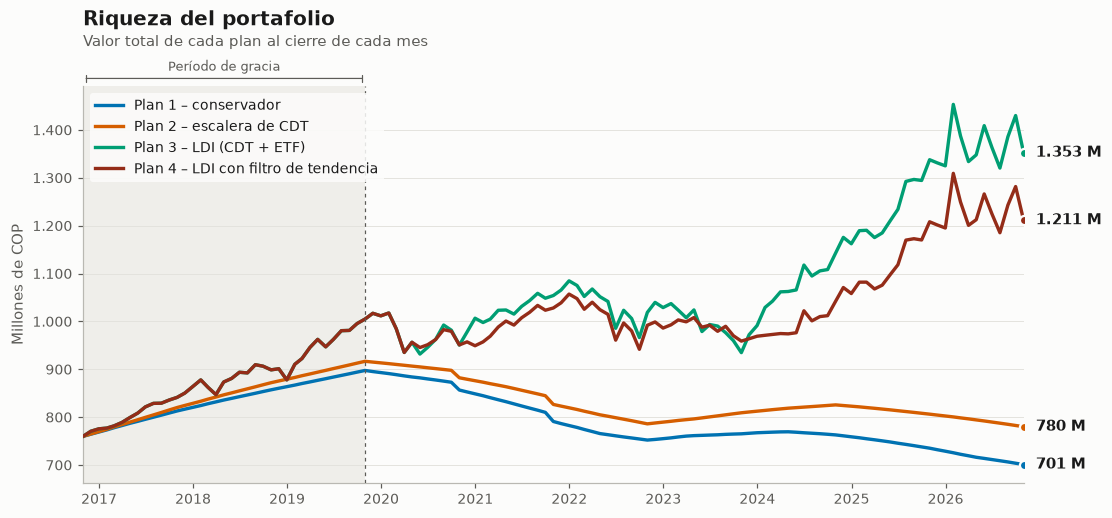

In [4]:
fig, ax_w = new_axes(
    "Riqueza del portafolio", "Millones de COP", "Valor total de cada plan al cierre de cada mes"
)
for plan, df in results.items():
    wealth = df["wealth_cop"] / 1e6
    ax_w.plot(df["date"], wealth, color=COLORS[plan], lw=2.2, label=PLANS[plan], zorder=3)
    # Final value at the right end of each line
    ax_w.plot(
        df["date"].iloc[-1], wealth.iloc[-1], "o", color=COLORS[plan], ms=6, mec=SURFACE, mew=1.5, zorder=4
    )
    ax_w.annotate(
        f"{es_number(wealth.iloc[-1])} M",
        (df["date"].iloc[-1], wealth.iloc[-1]),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        color=TEXT,
        fontweight="bold",
        annotation_clip=False,
    )
ax_w.legend(loc="upper left", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.85)
plt.show()

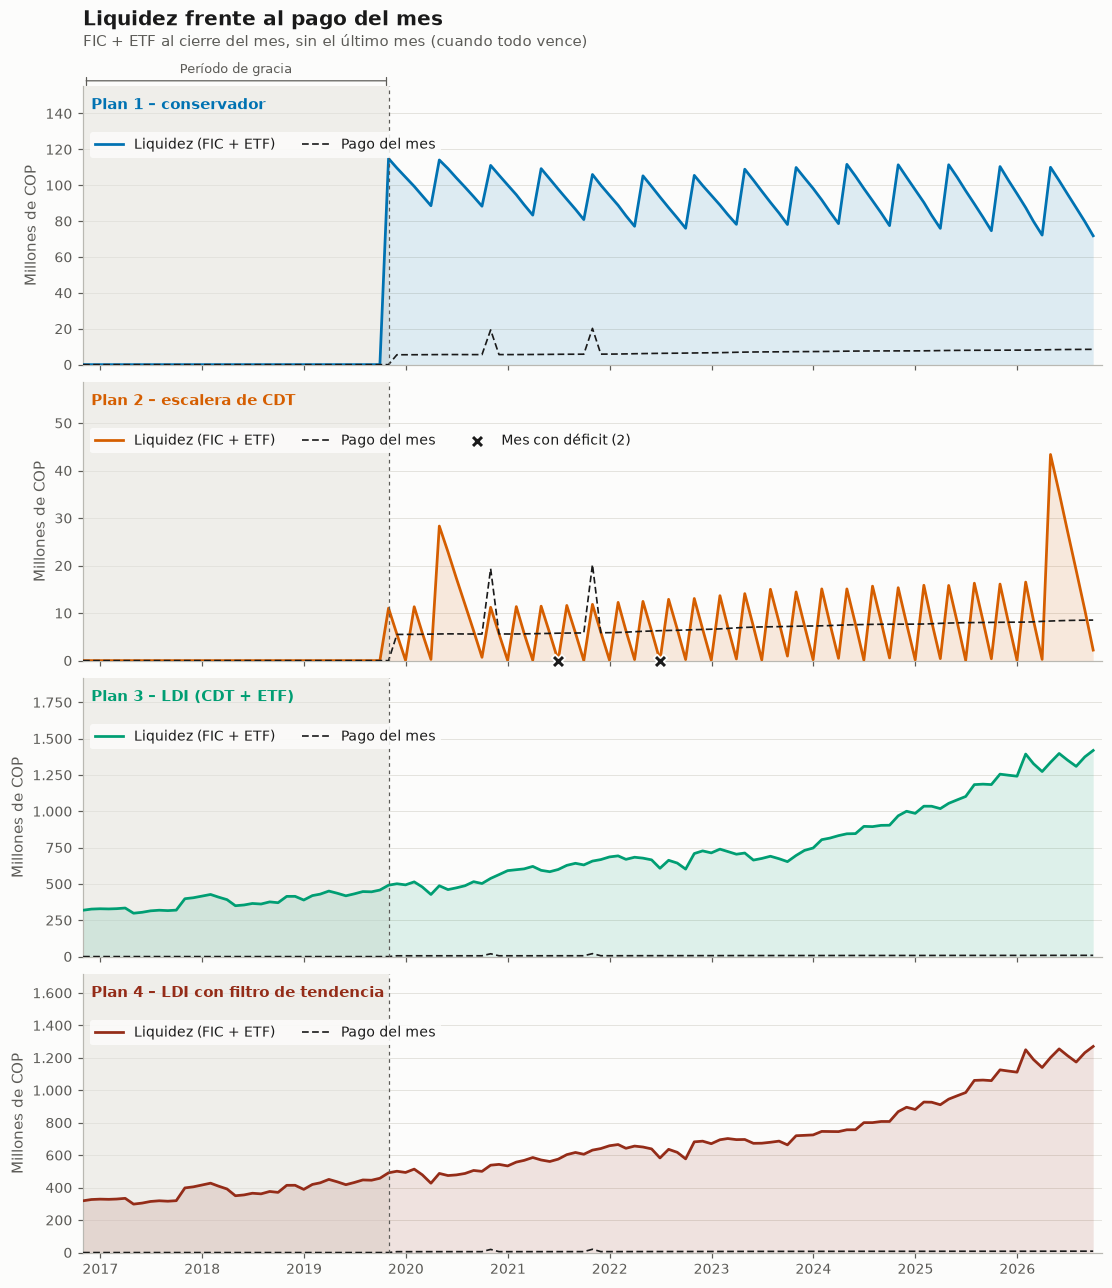

In [5]:
# Liquidez: FIC + ETF de cada plan (el ETF se vende si el FIC no alcanza) frente al pago del mes.
# Un panel por plan, cada uno con su escala: la liquidez del plan 3 aplastaría a la de los otros dos.
# Sin el último mes: en el mes H vencen todos los CDT y la escala no dejaría ver el resto.
last_month = bt["horizon_months"]
payments = results["conservative"].query("month < @last_month")
fig, axes = plt.subplots(len(results), 1, figsize=(10, 2.9 * len(results)), sharex=True, layout="constrained")
for ax, (plan, df) in zip(axes, results.items(), strict=True):
    style_axes(ax, "Millones de COP")
    df = df[df["month"] < last_month]
    liquid = (df["fic_cop"] + df["etf_cop"]) / 1e6
    ax.fill_between(df["date"], liquid, color=COLORS[plan], alpha=0.12, lw=0, zorder=1)
    ax.plot(df["date"], liquid, color=COLORS[plan], lw=1.8, label="Liquidez (FIC + ETF)", zorder=3)
    ax.plot(
        payments["date"],
        payments["payment_cop"] / 1e6,
        color=TEXT,
        lw=1.1,
        ls=(0, (4, 2)),
        label="Pago del mes",
        zorder=3,
    )
    short = df["shortfall_cop"] > 0
    ax.scatter(
        df["date"][short],
        liquid[short],
        s=80,
        marker="X",
        color=TEXT,
        edgecolor=SURFACE,
        linewidth=1.2,
        zorder=5,
        clip_on=False,
        label=f"Mes con déficit ({short.sum()})" if short.any() else None,
    )
    ax.set_ylim(bottom=0)
    ax.set_ylim(top=liquid.max() * 1.35)  # headroom for the plan name and the legend
    ax.text(0.008, 0.96, PLANS[plan], transform=ax.transAxes, va="top", fontweight="bold", color=COLORS[plan])
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(0, 0.86),
        ncols=3,
        frameon=True,
        facecolor=SURFACE,
        edgecolor="none",
        framealpha=0.85,
    )
add_header(
    axes[0],
    "Liquidez frente al pago del mes",
    "FIC + ETF al cierre del mes, sin el último mes (cuando todo vence)",
)
plt.show()

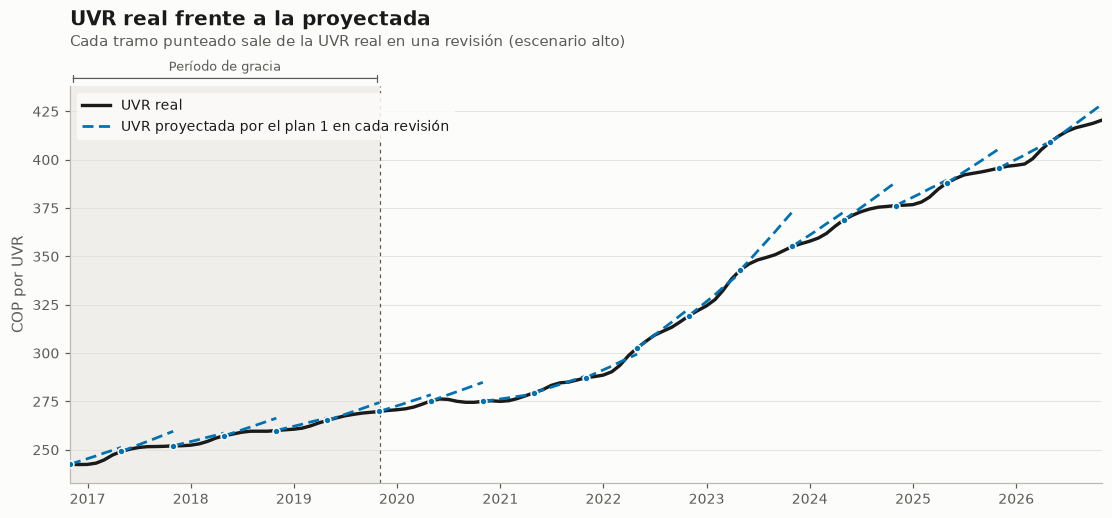

In [6]:
# UVR real en tinta; las proyecciones del plan 1 en su color, dibujadas encima (zorder mayor)
fig, ax_u = new_axes(
    "UVR real frente a la proyectada",
    "COP por UVR",
    f"Cada tramo punteado sale de la UVR real en una revisión "
    f"({'escenarios bajo, base y alto' if CASE else 'escenario ' + SCENARIO_NAMES[scenario]})",
)
ax_u.plot(dates, uvr_real.values, color=TEXT, lw=2.2, label="UVR real", zorder=2)
PROJECTION_STYLE = {  # label, color and dashes of each scenario when the run is shown
    "low": ("UVR proyectada, escenario bajo", "#0072B2", (0, (1, 2))),
    "base": ("UVR proyectada, escenario base", "#009E73", (0, (4, 2))),
    "high": ("UVR proyectada, escenario alto", "#D55E00", (0, (5, 1, 1, 1))),
}
for name, segments in projections.items():
    if CASE:
        label, color, dashes = PROJECTION_STYLE[name]
    else:
        label, color, dashes = "UVR proyectada por el plan 1 en cada revisión", COLORS["conservative"], (0, (4, 2))
    for i, p in enumerate(segments):
        ax_u.plot(p.index, p.values, color=color, lw=1.8, ls=dashes, label=label if i == 0 else None, zorder=3)
        ax_u.plot(p.index[0], p.values[0], "o", color=color, ms=4.5, mec=SURFACE, mew=1, zorder=4)
ax_u.legend(loc="upper left", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.85)
plt.show()

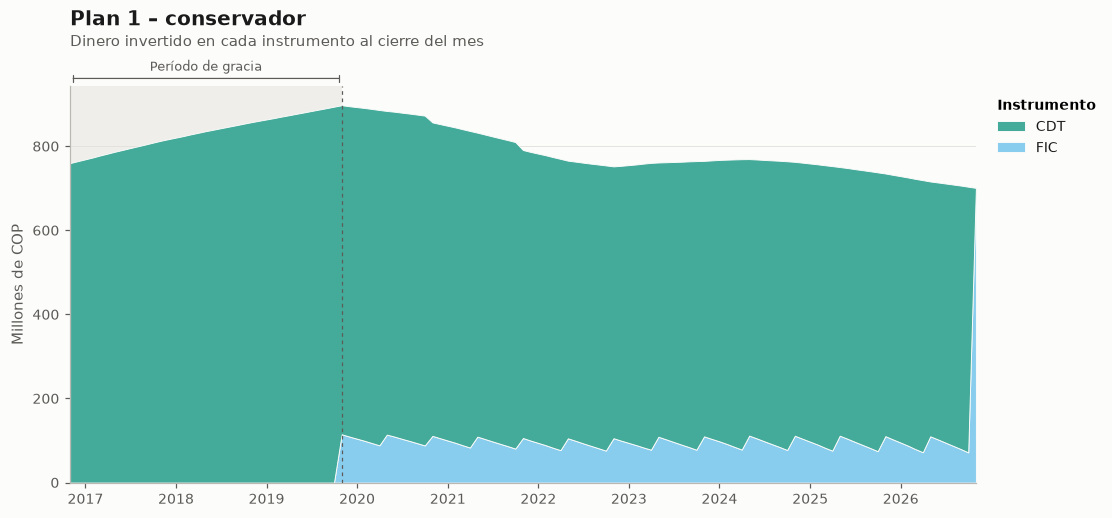

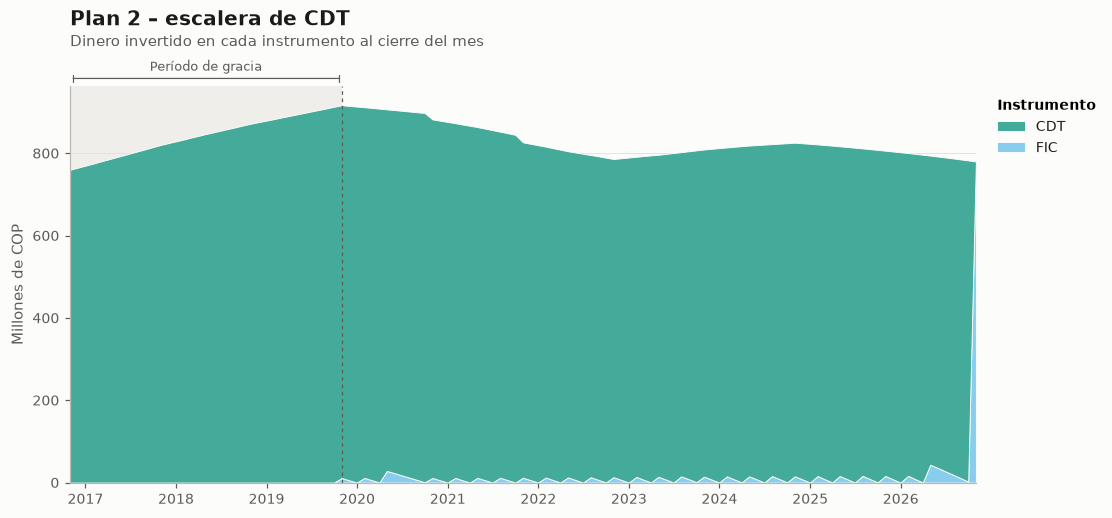

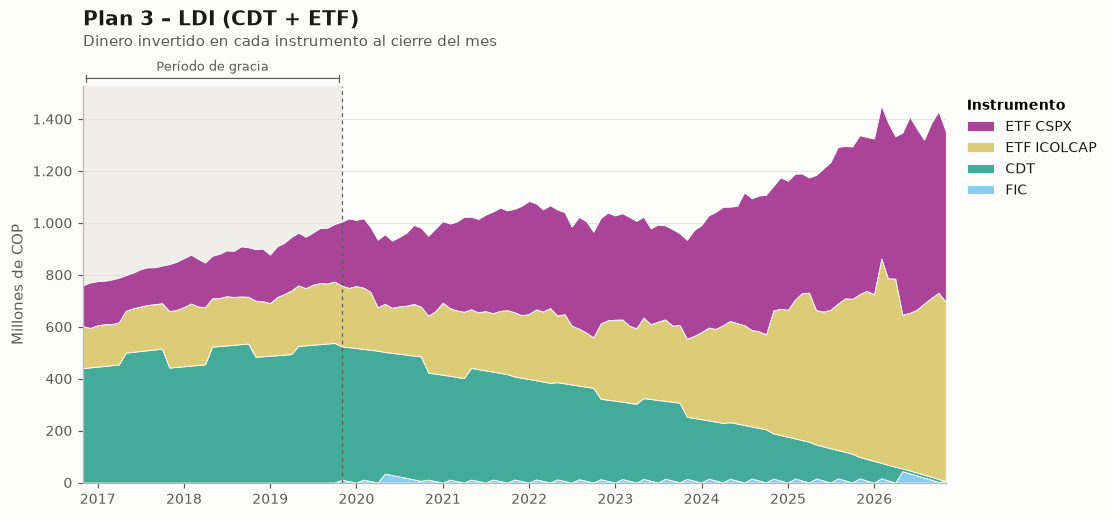

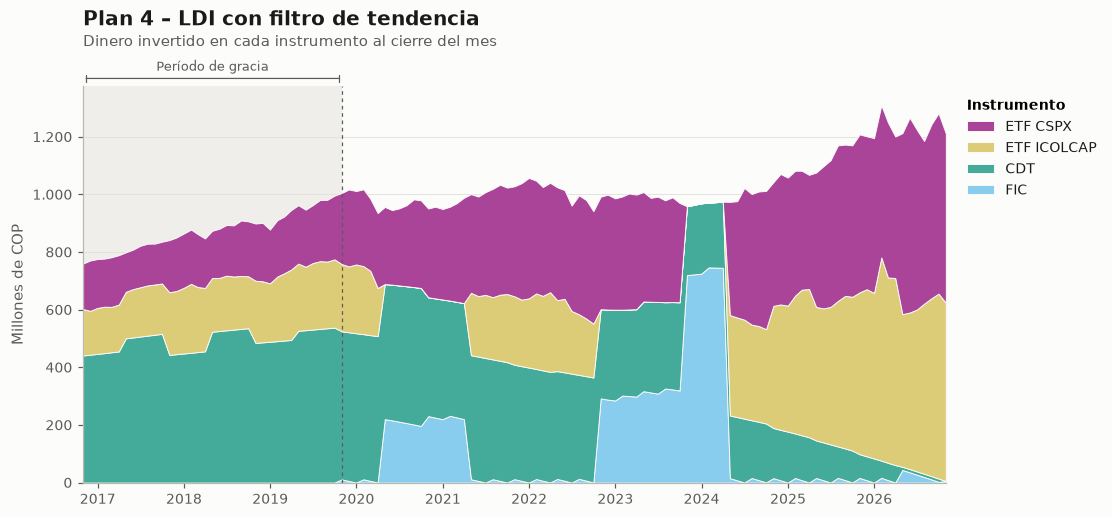

In [7]:
# Dinero en cada instrumento al cierre del mes, apilado (el total es la riqueza del plan)
INSTRUMENTS = {
    "fic_cop": ("FIC", "#88CCEE"),
    "cdt_cop": ("CDT", "#44AA99"),
    "icolcap_cop": ("ETF ICOLCAP", "#DDCC77"),
    "cspx_cop": ("ETF CSPX", "#AA4499"),
}


def stacked(ax, df, series: dict):
    """Stacked areas with a thin light border between layers; legend outside, in the order of the stack."""
    ax.stackplot(
        df["date"],
        list(series.values()),
        colors=[INSTRUMENTS[col][1] for col in series],
        labels=[INSTRUMENTS[col][0] for col in series],
        edgecolor=SURFACE,
        linewidth=0.6,
        zorder=2,
    )
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles[::-1],
        labels[::-1],
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        title="Instrumento",
        title_fontproperties={"weight": "bold", "size": 9},
        alignment="left",
    )


for plan, df in results.items():
    used = [col for col in INSTRUMENTS if df[col].abs().max() > 0]  # solo los instrumentos que el plan usa
    fig, ax = new_axes(
        PLANS[plan], "Millones de COP", "Dinero invertido en cada instrumento al cierre del mes"
    )
    stacked(ax, df, {col: df[col] / 1e6 for col in used})
    ax.set_ylim(bottom=0)
    plt.show()

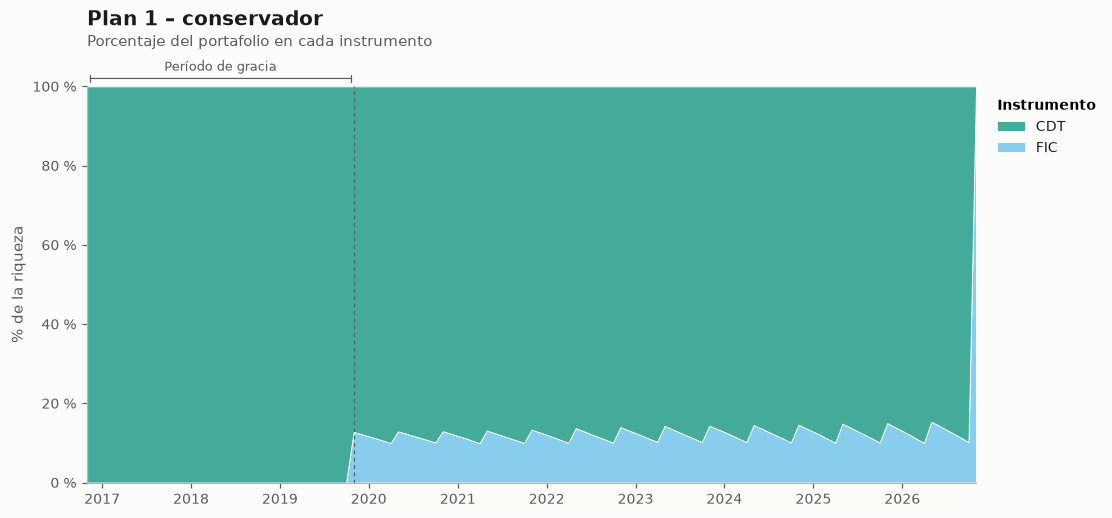

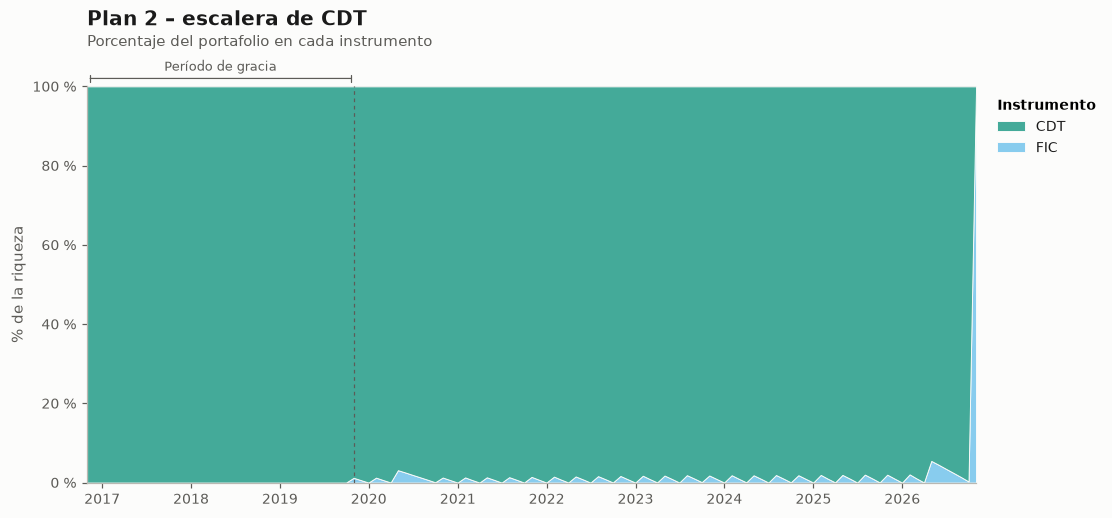

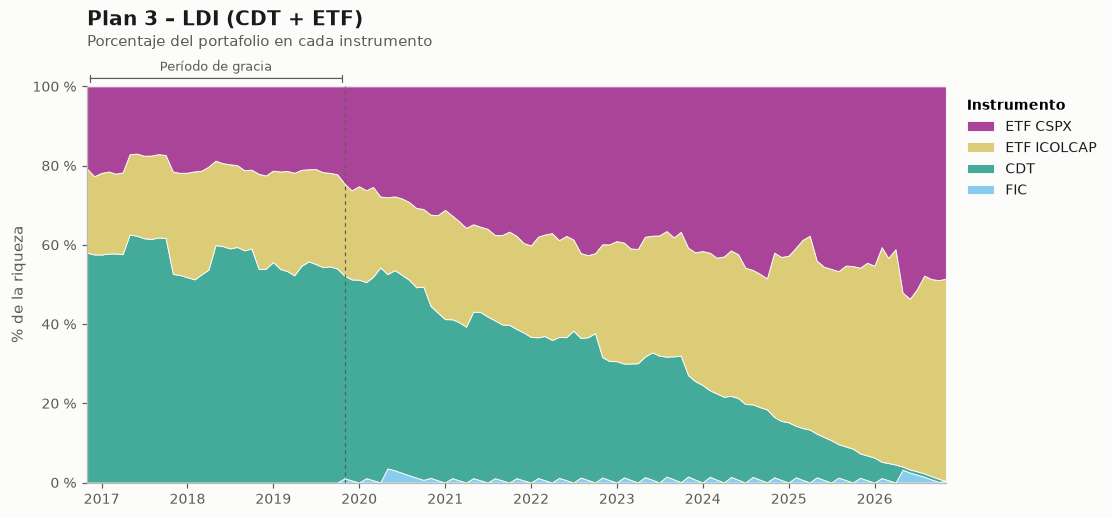

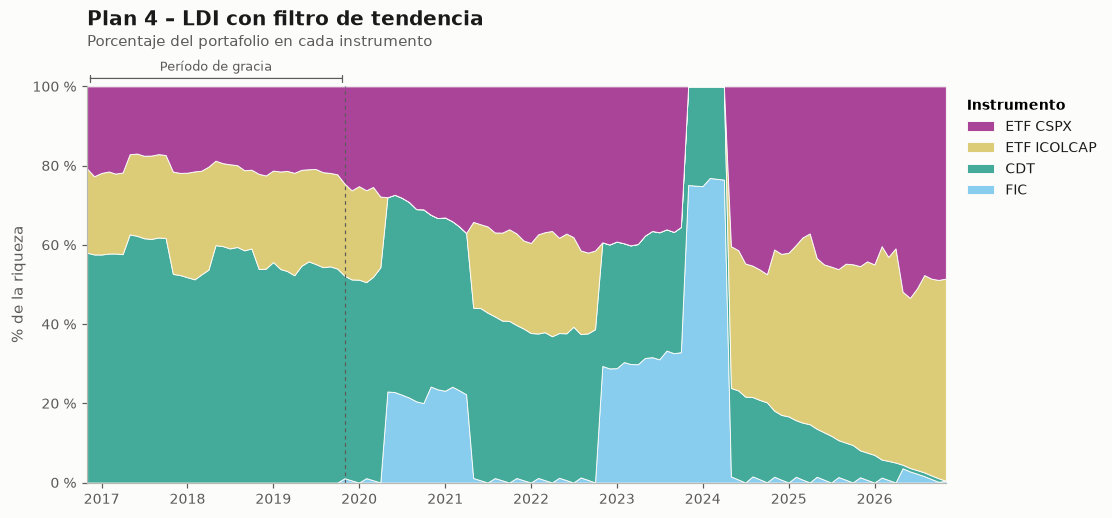

In [8]:
# Lo mismo en porcentaje: la suma de los instrumentos es 100 % en cada mes
for plan, df in results.items():
    used = [col for col in INSTRUMENTS if df[col].abs().max() > 0]
    share = df[used].div(df[used].sum(axis=1), axis=0) * 100
    fig, ax = new_axes(
        PLANS[plan], "% de la riqueza", "Porcentaje del portafolio en cada instrumento", shade_grace=False
    )
    stacked(ax, df, {col: share[col] for col in used})
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f} %"))
    plt.show()